# 04 QCBM Hardware Execution

This notebook executes the trained QCBM circuit on IBM Quantum hardware.

The trained parameters are reused from:

```text
results/qcbm_statevector/qcbm_statevector_parameters.npy

Trained QCBM parameters
        ↓
Hardware-aware QCBM circuit
        ↓
IBM Quantum backend
        ↓
Sampler execution
        ↓
Bitstring counts
        ↓
Hardware probability distribution
        ↓
Distribution metrics
        ↓
Cluster-based molecular retrieval
        ↓
Molecular quality evaluation

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(
        0,
        str(SRC_DIR)
    )

print("PROJECT_ROOT =", PROJECT_ROOT)
print("SRC_DIR =", SRC_DIR)

PROJECT_ROOT = d:\QCBM Molecular Augmentation Lite
SRC_DIR = d:\QCBM Molecular Augmentation Lite\src


In [2]:
import os
import json
import time
import random
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qiskit_ibm_runtime import (
    QiskitRuntimeService
)

from qiskit import transpile

from qiskit.visualization import (
    plot_histogram
)

from rdkit import RDLogger

RDLogger.DisableLog("rdApp.*")

from molaug_qcbm.hardware.topology import (
    HardwareTopology
)

from molaug_qcbm.hardware.hardware_circuit import (
    HardwareQCBMCircuit
)

from molaug_qcbm.hardware.hardware_sampler import (
    HardwareSampler
)

from molaug_qcbm.hardware.hardware_results import (
    HardwareResults
)

from molaug_qcbm.preprocessing.selfies import (
    safe_selfies
)

from molaug_qcbm.encoding.kmeans import (
    selfies_to_latent,
    KMeansEncoder
)

from molaug_qcbm.augmentation.retrieval import (
    EmpiricalClusterRetriever
)

from molaug_qcbm.evaluation.benchmark_metrics import (
    distribution_report
)

from molaug_qcbm.evaluation.validity import (
    validity_report
)

from molaug_qcbm.evaluation.uniqueness import (
    uniqueness_report
)

from molaug_qcbm.evaluation.novelty import (
    novelty_report
)

from molaug_qcbm.evaluation.qed import (
    qed_report,
    qed_dataframe
)

from molaug_qcbm.evaluation.sa_score import (
    sa_report,
    sa_dataframe
)

from molaug_qcbm.evaluation.syba import (
    syba_report,
    syba_score_smiles
)

print("Imports complete.")

Imports complete.


In [3]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

PROJECT_ROOT = r"D:\QCBM Molecular Augmentation Lite"

DATA_DIR = os.path.join(
    PROJECT_ROOT,
    "data"
)

BENCHMARK_DIR = os.path.join(
    DATA_DIR,
    "benchmark_splits"
)

STATEVECTOR_RESULTS_DIR = os.path.join(
    PROJECT_ROOT,
    "results",
    "qcbm_statevector"
)

HARDWARE_RESULTS_DIR = os.path.join(
    PROJECT_ROOT,
    "results",
    "qcbm_hardware"
)

os.makedirs(
    HARDWARE_RESULTS_DIR,
    exist_ok=True
)

TRAIN_PARQUET = os.path.join(
    BENCHMARK_DIR,
    "train.parquet"
)

PARAMETERS_PATH = os.path.join(
    STATEVECTOR_RESULTS_DIR,
    "qcbm_statevector_parameters.npy"
)

TARGET_DISTRIBUTION_PATH = os.path.join(
    STATEVECTOR_RESULTS_DIR,
    "target_distribution.npy"
)

STATEVECTOR_DISTRIBUTION_PATH = os.path.join(
    STATEVECTOR_RESULTS_DIR,
    "qcbm_statevector_distribution.npy"
)

N_QUBITS = 5
N_STATES = 2 ** N_QUBITS
N_CLUSTERS = N_STATES

N_LAYERS = 3

SHOTS = 4096

BACKEND_NAME = "ibm_fez"

N_TRAIN_SAMPLE = 20000

MAX_SELFIES_TOKENS = 32

print("Project root:", PROJECT_ROOT)
print("Backend:", BACKEND_NAME)
print("Qubits:", N_QUBITS)
print("States:", N_STATES)
print("Shots:", SHOTS)

Project root: D:\QCBM Molecular Augmentation Lite
Backend: ibm_fez
Qubits: 5
States: 32
Shots: 4096


In [4]:
TOKEN = "XWvaPB9wnINckzyGvpqAP3Z_HLW0ekQBkyL1wrwVnOfg"

INSTANCE = "crn:v1:bluemix:public:quantum-computing:us-east:a/09813719d754420c98b5084b26391e69:42e597da-bee3-4b93-8fc0-a36c231cbb72::"

QiskitRuntimeService.save_account(
    channel="ibm_cloud",
    token=TOKEN.strip(),
    instance=INSTANCE.strip(),
    name="default-ibm-cloud",
    overwrite=True,
    set_as_default=True
)

service = QiskitRuntimeService(
    name="default-ibm-cloud"
)

available_backends = service.backends()

print("Available backends:")
print(available_backends)

Available backends:
[<IBMBackend('ibm_fez')>, <IBMBackend('ibm_marrakesh')>, <IBMBackend('ibm_kingston')>]


In [5]:
backend = service.backend(
    BACKEND_NAME
)

print("Selected backend:", backend.name)
print("Backend object:", backend)

Selected backend: ibm_fez
Backend object: <IBMBackend('ibm_fez')>


In [6]:
try:

    status = backend.status()

    backend_status_df = pd.DataFrame(
        [
            {
                "backend": backend.name,
                "operational": status.operational,
                "pending_jobs": status.pending_jobs,
                "status_msg": status.status_msg
            }
        ]
    )

except Exception as e:

    backend_status_df = pd.DataFrame(
        [
            {
                "backend": backend.name,
                "operational": None,
                "pending_jobs": None,
                "status_msg": str(e)
            }
        ]
    )

backend_status_df

,backend,operational,pending_jobs,status_msg
0,ibm_fez,True,23,active


In [7]:
try:

    config = backend.configuration()

    backend_config = {
        "backend": backend.name,
        "num_qubits": config.num_qubits,
        "basis_gates": config.basis_gates,
        "simulator": config.simulator,
        "coupling_map_length": len(config.coupling_map)
    }

except Exception as e:

    backend_config = {
        "backend": backend.name,
        "error": str(e)
    }

backend_config

{'backend': 'ibm_fez',
 'num_qubits': 156,
 'basis_gates': ['cz', 'id', 'rz', 'sx', 'x'],
 'simulator': False,
 'coupling_map_length': 352}

## Hardware Topology

The hardware execution needs a connected 5-qubit path.

The topology module extracts the backend coupling map and finds a linear path suitable for a 5-qubit QCBM.

The logical QCBM uses:

```text
q0 - q1 - q2 - q3 - q4

In [8]:
topology = HardwareTopology(
    backend
)

topology_summary = topology.summary()

topology_summary

{'backend': 'ibm_fez',
 'num_qubits': 156,
 'num_edges': 352,
 'connected_components': 1}

In [9]:
physical_path = topology.best_qcbm_path(
    n_qubits=N_QUBITS
)

print("Selected physical path:", physical_path)

logical_to_physical = {
    logical: physical
    for logical, physical
    in enumerate(
        physical_path
    )
}

logical_to_physical_df = pd.DataFrame(
    [
        {
            "logical_qubit": k,
            "physical_qubit": v
        }
        for k, v
        in logical_to_physical.items()
    ]
)

logical_to_physical_df

Selected physical path: [0, 1, 2, 3, 16]


,logical_qubit,physical_qubit
0,0,0
1,1,1
2,2,2
3,3,3
4,4,16


In [10]:
theta = np.load(
    PARAMETERS_PATH
)

target_distribution = np.load(
    TARGET_DISTRIBUTION_PATH
)

statevector_distribution = np.load(
    STATEVECTOR_DISTRIBUTION_PATH
)

print("Theta shape:", theta.shape)
print("Target distribution shape:", target_distribution.shape)
print("Statevector distribution shape:", statevector_distribution.shape)

print("Target mass:", target_distribution.sum())
print("Statevector mass:", statevector_distribution.sum())

Theta shape: (30,)
Target distribution shape: (32,)
Statevector distribution shape: (32,)
Target mass: 1.0
Statevector mass: 1.0


In [11]:
expected_parameters = (
    N_LAYERS
    *
    N_QUBITS
    *
    2
)

print("Expected parameters:", expected_parameters)
print("Actual parameters:", len(theta))

assert len(theta) == expected_parameters, (
    "Parameter count mismatch. "
    "Check N_LAYERS and N_QUBITS."
)

Expected parameters: 30
Actual parameters: 30


In [12]:
hardware_circuit_builder = HardwareQCBMCircuit(
    physical_qubits=physical_path,
    n_layers=N_LAYERS,
    measure=True
)

hardware_circuit_summary = (
    hardware_circuit_builder.summary()
)

hardware_circuit_summary

{'n_qubits': 5,
 'n_layers': 3,
 'parameters': 30,
 'physical_qubits': [0, 1, 2, 3, 16],
 'measurement': True}

     ┌────────────┐┌────────────┐   ┌────────────┐┌────────────┐              »
q_0: ┤ Ry(2.5148) ├┤ Rz(6.1519) ├─■─┤ Ry(1.4782) ├┤ Rz(6.0625) ├──────────────»
     ├────────────┤├────────────┤ │ └────────────┘├────────────┤┌────────────┐»
q_1: ┤ Ry(5.0156) ├┤ Rz(5.8599) ├─■───────■───────┤ Ry(5.5755) ├┤ Rz(1.8251) ├»
     ├────────────┤├────────────┤         │       └────────────┘├───────────┬┘»
q_2: ┤ Ry(1.4617) ├┤ Rz(1.1303) ├─────────■─────────────■───────┤ Ry(1.138) ├─»
     ├────────────┤├────────────┤                       │       └───────────┘ »
q_3: ┤ Ry(1.4035) ├┤ Rz(4.7126) ├───────────────────────■─────────────■───────»
     ├────────────┤├────────────┤                                     │       »
q_4: ┤ Ry(4.8105) ├┤ Rz(4.8958) ├─────────────────────────────────────■───────»
     └────────────┘└────────────┘                                             »
c: 5/═════════════════════════════════════════════════════════════════════════»
                                        

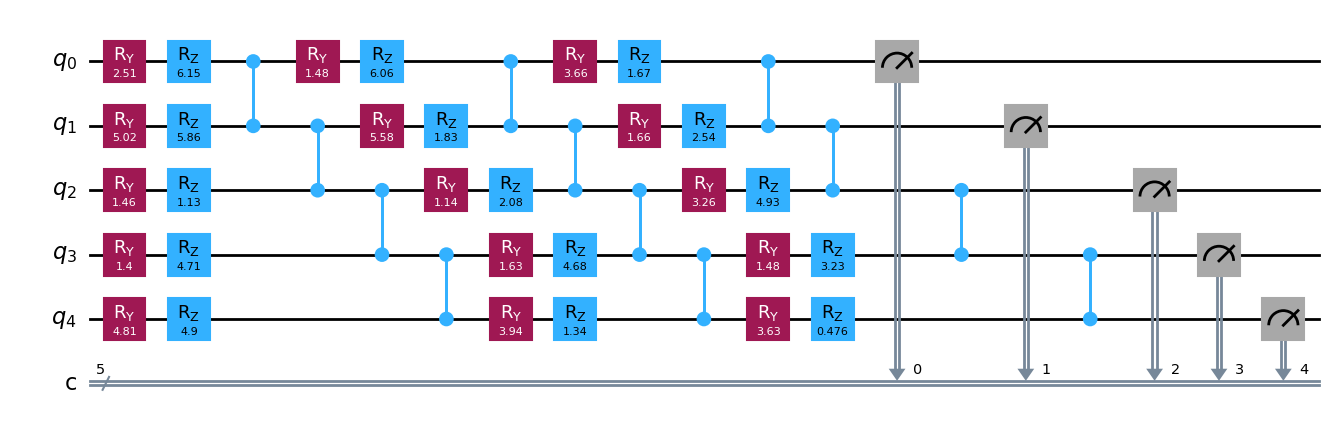

In [13]:
hardware_circuit = hardware_circuit_builder.build(
    theta
)

print(hardware_circuit)

hardware_circuit.draw(
    "mpl"
)

Original depth: 15
Transpiled depth: 21
Original gates: OrderedDict([('ry', 15), ('rz', 15), ('cz', 12), ('measure', 5)])
Transpiled gates: OrderedDict([('sx', 30), ('rz', 30), ('cz', 12), ('measure', 5)])


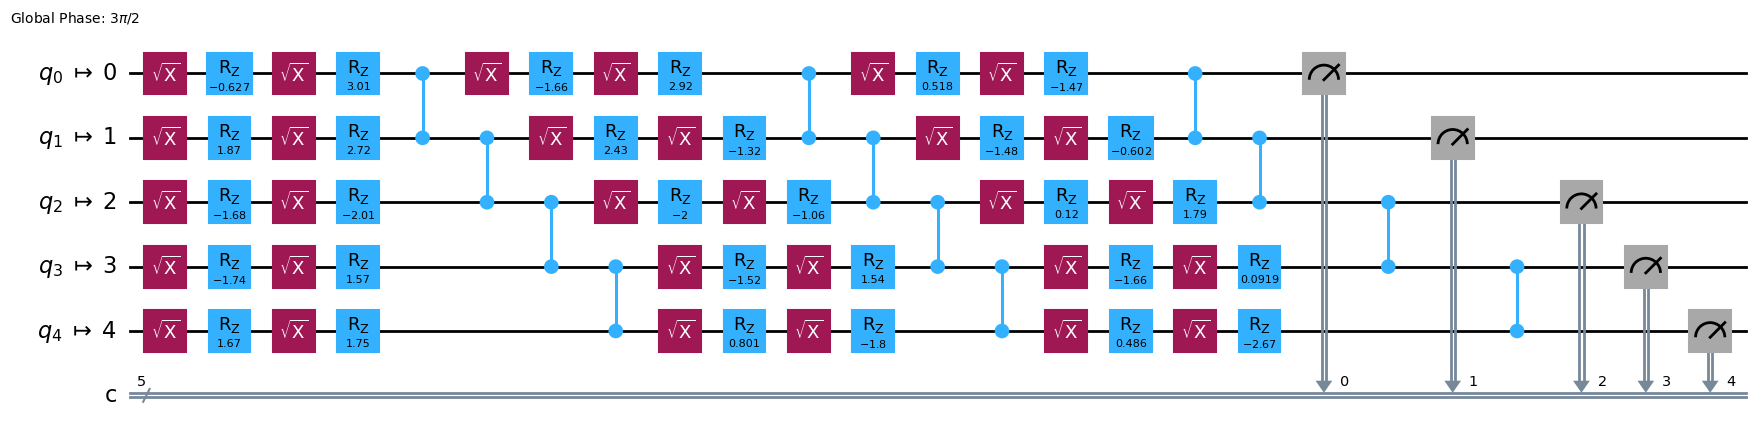

In [14]:
transpiled_circuit = transpile(
    hardware_circuit,
    backend=backend,
    optimization_level=1
)

print("Original depth:", hardware_circuit.depth())
print("Transpiled depth:", transpiled_circuit.depth())
print("Original gates:", hardware_circuit.count_ops())
print("Transpiled gates:", transpiled_circuit.count_ops())

transpiled_circuit.draw(
    "mpl"
)

In [15]:
circuit_metadata = {
    "backend": BACKEND_NAME,
    "n_qubits": N_QUBITS,
    "n_states": N_STATES,
    "n_layers": N_LAYERS,
    "shots": SHOTS,
    "physical_path": physical_path,
    "logical_to_physical": logical_to_physical,
    "original_depth": hardware_circuit.depth(),
    "transpiled_depth": transpiled_circuit.depth(),
    "original_ops": {
        str(k): int(v)
        for k, v
        in hardware_circuit.count_ops().items()
    },
    "transpiled_ops": {
        str(k): int(v)
        for k, v
        in transpiled_circuit.count_ops().items()
    }
}

with open(
    os.path.join(
        HARDWARE_RESULTS_DIR,
        "hardware_circuit_metadata.json"
    ),
    "w"
) as f:

    json.dump(
        circuit_metadata,
        f,
        indent=4
    )

circuit_metadata

{'backend': 'ibm_fez',
 'n_qubits': 5,
 'n_states': 32,
 'n_layers': 3,
 'shots': 4096,
 'physical_path': [0, 1, 2, 3, 16],
 'logical_to_physical': {0: 0, 1: 1, 2: 2, 3: 3, 4: 16},
 'original_depth': 15,
 'transpiled_depth': 21,
 'original_ops': {'ry': 15, 'rz': 15, 'cz': 12, 'measure': 5},
 'transpiled_ops': {'sx': 30, 'rz': 30, 'cz': 12, 'measure': 5}}

## Hardware Execution

The circuit is executed using `SamplerV2`.

The hardware sampler module performs:

```text
Circuit
↓
Transpilation
↓
IBM Runtime Sampler
↓
Job submission
↓
Result extraction
↓
Counts extraction

In [16]:
hardware_sampler = HardwareSampler(
    backend
)

start_time = time.perf_counter()

job = hardware_sampler.run(
    circuit=hardware_circuit,
    shots=SHOTS
)

submission_time = time.perf_counter() - start_time

print("Job submitted.")
print("Submission time:", submission_time)

try:
    print("Job ID:", job.job_id())
except Exception:
    print("Job ID unavailable.")

Job submitted.
Submission time: 2.3109267999971053
Job ID: d8ueh0kbp3hs7385ru20


In [17]:
try:

    job_id = job.job_id()

except Exception:

    job_id = None

job_info = {
    "backend": BACKEND_NAME,
    "job_id": job_id,
    "shots": SHOTS,
    "submission_time_sec": submission_time
}

with open(
    os.path.join(
        HARDWARE_RESULTS_DIR,
        "hardware_job_info.json"
    ),
    "w"
) as f:

    json.dump(
        job_info,
        f,
        indent=4
    )

job_info

{'backend': 'ibm_fez',
 'job_id': 'd8ueh0kbp3hs7385ru20',
 'shots': 4096,
 'submission_time_sec': 2.3109267999971053}

In [22]:
print("=" * 80)
print("IBM HARDWARE JOB SUBMITTED")
print("=" * 80)

print(f"Backend           : {BACKEND_NAME}")
print(f"Job ID            : {job_id}")
print(f"Shots             : {SHOTS}")
print(f"Submission Time   : {submission_time:.2f} sec")

print("=" * 80)

IBM HARDWARE JOB SUBMITTED
Backend           : ibm_fez
Job ID            : d8ueh0kbp3hs7385ru20
Shots             : 4096
Submission Time   : 2.31 sec


In [25]:
from qiskit import qpy

qpy_path = os.path.join(
    HARDWARE_RESULTS_DIR,
    "hardware_circuit.qpy"
)

with open(qpy_path, "wb") as f:

    qpy.dump(
        transpiled_circuit,
        f
    )

print(qpy_path)

D:\QCBM Molecular Augmentation Lite\results\qcbm_hardware\hardware_circuit.qpy


In [26]:
figure = transpiled_circuit.draw(
    output="mpl",
    fold=-1
)

figure.savefig(
    os.path.join(
        HARDWARE_RESULTS_DIR,
        "hardware_circuit.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close(figure)

In [27]:
experiment_config = {

    "backend": BACKEND_NAME,

    "job_id": job_id,

    "shots": SHOTS,

    "n_qubits": N_QUBITS,

    "n_states": N_STATES,

    "n_clusters": N_CLUSTERS,

    "n_layers": N_LAYERS
}

with open(

    os.path.join(
        HARDWARE_RESULTS_DIR,
        "experiment_config.json"
    ),

    "w"

) as f:

    json.dump(
        experiment_config,
        f,
        indent=4
    )

experiment_config

{'backend': 'ibm_fez',
 'job_id': 'd8ueh0kbp3hs7385ru20',
 'shots': 4096,
 'n_qubits': 5,
 'n_states': 32,
 'n_clusters': 32,
 'n_layers': 3}

In [29]:
backend_metadata = {

    "backend_name":
        backend.name,

    "backend_version":
        backend.backend_version,

    "num_qubits":
        backend.num_qubits,

    "basis_gates":
        config.basis_gates,

    "coupling_map":
        config.coupling_map
}

with open(

    os.path.join(
        HARDWARE_RESULTS_DIR,
        "backend_metadata.json"
    ),

    "w"

) as f:

    json.dump(
        backend_metadata,
        f,
        indent=4,
        default=str
    )

backend_metadata

{'backend_name': 'ibm_fez',
 'backend_version': '1.3.37',
 'num_qubits': 156,
 'basis_gates': ['cz', 'id', 'rz', 'sx', 'x'],
 'coupling_map': [[0, 1],
  [1, 0],
  [1, 2],
  [2, 1],
  [2, 3],
  [3, 2],
  [3, 4],
  [3, 16],
  [4, 3],
  [4, 5],
  [5, 4],
  [5, 6],
  [6, 5],
  [6, 7],
  [7, 6],
  [7, 8],
  [7, 17],
  [8, 7],
  [8, 9],
  [9, 8],
  [9, 10],
  [10, 9],
  [10, 11],
  [11, 10],
  [11, 12],
  [11, 18],
  [12, 11],
  [12, 13],
  [13, 12],
  [13, 14],
  [14, 13],
  [14, 15],
  [15, 14],
  [15, 19],
  [16, 3],
  [16, 23],
  [17, 7],
  [17, 27],
  [18, 11],
  [18, 31],
  [19, 15],
  [19, 35],
  [20, 21],
  [21, 20],
  [21, 22],
  [21, 36],
  [22, 21],
  [22, 23],
  [23, 16],
  [23, 22],
  [23, 24],
  [24, 23],
  [24, 25],
  [25, 24],
  [25, 26],
  [25, 37],
  [26, 25],
  [26, 27],
  [27, 17],
  [27, 26],
  [27, 28],
  [28, 27],
  [28, 29],
  [29, 28],
  [29, 30],
  [29, 38],
  [30, 29],
  [30, 31],
  [31, 18],
  [31, 30],
  [31, 32],
  [32, 31],
  [32, 33],
  [33, 32],
  [33, 34],
 

In [30]:
summary = pd.DataFrame(
    [
        {
            "Backend": BACKEND_NAME,
            "Job ID": job_id,
            "Shots": SHOTS,
            "Submission Time (s)": submission_time
        }
    ]
)

summary

,Backend,Job ID,Shots,Submission Time (s)
0,ibm_fez,d8ueh0kbp3hs7385ru20,4096,2.310927


# Hardware Experiment Summary

This notebook successfully submitted the baseline 5-qubit QCBM to IBM Quantum hardware (`ibm_fez`).

The following artifacts were generated:

- hardware_job_info.json
- experiment_config.json
- backend_metadata.json
- hardware_circuit.qpy
- hardware_circuit.png

The IBM Quantum Job ID has been stored for future retrieval.

During repository development, the notebook intentionally stops after successful submission rather than waiting for execution. Queue times vary substantially and are independent of the algorithm. Hardware results for all QCBM variants (Baseline, Chow-Liu, KMeans, GNN, Latent, and RL) will be collected together in the final benchmarking stage using the saved Job IDs.